In [1]:
from invisible_cities.cities.components import deconv_pmt, load_dst
from invisible_cities.core.core_functions import in_range
from invisible_cities.database  import load_db
import pandas as pd
import numpy as np
import tables as tb
import os
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from pathlib  import Path
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
import sys
from datetime import datetime
from scipy.stats import trim_mean


In [2]:
def find_highest_wf(wfs, event_number):
    assert len(wfs.shape) == 3, "input must be 3-dimensional"

    wfs   = wfs[event_number]
    index = np.argmax(np.max(wfs, axis=1))
    print(index)
    return wfs[index]

def sum_wf(wfs):
    element_wise_sum = np.zeros_like(wfs[0])

    # Sum the arrays element-wise
    for array in wfs:
        element_wise_sum += array

    return element_wise_sum

def ADC_to_PE(wfs, datapmt):
    conv_factors = datapmt.adc_to_pes.to_numpy()

    for w in range(0, len(wfs)):
        if (conv_factors[w] == 1e5):
             wfs[w] = wfs[w]*0
        elif (conv_factors[w] == 0):
            wfs[w] = wfs[w]*0
        else:
            wfs[w] = wfs[w]/conv_factors[w]

    return wfs

# Look a the summed waveform and look for S1/S2 peaks in the grass region. 
def check_summed_baseline(wfs_sum, grass_lim, S1_height):

    flag=False
    tc=25e-3
    
    # Check the baseline at the end and start match
    # otherwise there could be signal there so the baseline is all messed up
    num_samples = int(25/tc)
    baseline1=np.mean(wfs_sum[-num_samples:])
    baseline2=np.mean(wfs_sum[0:int(25/tc)])

    # Check if the baseline varies by more than 0.1 PE
    if (abs(baseline1-baseline2) > 0.2):
        print("Error in baselines at start and end, dropping event")
        print(baseline1-baseline2)
        flag = True

    # Look in the window for large peaks that could be other S1/S2 pulses. 
    # This will mess up the reconstruction
    peaks, _ = find_peaks(wfs_sum[ int(grass_lim[0]/tc):int(grass_lim[1]/tc)], height=S1_height, distance=30/tc)

    bin_fact=100 # rebin amount
    wfs_sum_binned = rebin_array(wfs_sum, bin_fact)
    peaks_rebin, _ = find_peaks(wfs_sum_binned[ int(grass_lim[0]/(tc*bin_fact)):int(grass_lim[1]/(tc*bin_fact))], height=0.6)
    peaks_rebin = peaks_rebin*bin_fact

    peaks_filt = np.append(peaks, peaks_rebin)

    return flag, peaks_filt

# Searche for single PEs in the grass window. 
def get_PEs_inWindow(times, wfs, noise, thr_split, peak_minlen, peak_maxlen, half_window, window, event, ts, tc):

    rows = []

    tsel_     = in_range(times, *window)
    wfs = wfs[:, tsel_]

    for pmt_no, wf in enumerate(wfs):

        idx_over_thr = np.argwhere(wf > noise[pmt_no]).flatten() # Find the indices where the waveform is above the noise threshold
        splits       = np.argwhere(np.diff(idx_over_thr) > thr_split).flatten() # Find the indices where the difference between consecutive indices is greater than thr_split
        idx_slices   = np.split(idx_over_thr, splits+1) # Split the indices into slices based on the splits
        idx_slices   = list(filter(lambda sl: in_range(len(sl), peak_minlen, peak_maxlen + .5), idx_slices)) # Filter the slices to keep only those with length between peak_minlen and peak_maxlen

        for sl in idx_slices:
            m = np.argmax(wf[sl]) + sl[0] # Find the index of the maximum value in the slice and add the starting index of the slice to get the index in the original waveform
            pe_int = wf[max(m-half_window, 0):m+half_window].sum()*tc
            rows.append(dict(event = event, ts_raw=ts/1e3, pmt=pmt_no, pe_int=pe_int, peak_time=m*tc+window[0], noise_thr=noise[pmt_no]))

    return pd.DataFrame(rows, columns=["event", "ts_raw", "pmt", "pe_int", "peak_time", "noise_thr"])


def CorrectRawBaseline(wfs):

    corrected_waveforms = []

    for wfm in wfs:
        num_samples = int(25/tc)
        baseline1=np.mean(wfm[-num_samples:])
        baseline2=np.mean(wfm[0:int(25/tc)])
        wfm = -1*(wfm-baseline2)
        corrected_waveforms.append(wfm)

    return np.array(corrected_waveforms)

# Rebin a waveform
def rebin_array(arr, bin_size):
    new_len = len(arr) // bin_size  # Ensure integer division
    return np.mean(arr[:new_len * bin_size].reshape(new_len, bin_size), axis=1)


In [3]:
filename = "../data/run_16173_0000_ldc1_trg0.waveforms.h5"

raw_evts = pd.read_hdf(filename, '/Run/events')
print(raw_evts.evt_number.unique())

raw_evts = load_dst(filename, 'Run', 'events')
nrwfs = len(raw_evts.evt_number.unique())
print("Number of Waveforms:", nrwfs)

[  1   8  15  22  29  36  43  50  57  64  71  78  85  92  99 106 113 120
 127 134 141 148 155 162 169 176 183 190 197 204 211 218 225 232 239 246
 253 260 267 274 281 288 295 302 309 316 323 330 337 344 351 358]
Number of Waveforms: 52


In [4]:
# Load in the database for SiPMs

RUN_NUMBER = 16173

mask=False

deconv = deconv_pmt("next100", RUN_NUMBER, 62400, mask=mask)

detector_db = "next100"
datasipm = load_db.DataSiPM(detector_db, RUN_NUMBER)
datapmt = load_db.DataPMT(detector_db, RUN_NUMBER)

pmt_active = np.nonzero(datapmt.Active.values)[0].tolist() if mask else np.ones(len(datapmt), dtype=bool)
coeff_c    = datapmt.coeff_c  .values.astype(np.double)[pmt_active]
print(len(coeff_c))

tc          = 25e-3     # constant to convert from samples to time or vice versa. 
thr_split   = 2         # maximum number of samples allowed to be below threshold to consider it a peak
peak_minlen = 2         # minimum number of samples above threshold in a peak
peak_maxlen = 1.5/tc # maximum number of samples above threshold in a peak
half_window = 4         # number of samples to each side of a peak maximum to integrate
noise_sigma = 4         # how many STD above noise for the single PEs to be
S1_pad = 1              # How many mus for S1 peak search
useRaw = False

grass_lim   = list([0, 2600])
buffer_len  = 2600
noise_lim   = list([0, 90])
S1_height   = 4
S1_window   = 0, 2600
dead_pmts = [39, 36, 42, 46] 

print("Active PMTs:", pmt_active)

60
Active PMTs: [ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True]


In [5]:
def get_charge_inWindow(times, wfs, noise, thr_split, peak_minlen, peak_maxlen,
                            pad, window, event, tc, label):
    """
    thr_split   : gaps of up to this many samples below threshold are merged (0 = strict)
    peak_minlen : minimum width in samples (inclusive)
    peak_maxlen : maximum width in samples, or None for no upper limit
    pad         : extra samples integrated either side of the threshold crossings
    """
    rows = []

    # Cut the waveform to the window of interest
    tsel_ = in_range(times, *window)
    wfs   = wfs[:, tsel_]
    nsamp = wfs.shape[1]

    for pmt_no, wf in enumerate(wfs):

        # Mark samples above threshold and find rising and falling edges
        above  = np.concatenate(([0], (wf > noise[pmt_no]).astype(int), [0]))
        edges  = np.diff(above)
        starts = np.flatnonzero(edges == 1)    # first sample above threshold
        ends   = np.flatnonzero(edges == -1)   # one past the last sample above threshold

        if len(starts) == 0:
            continue

        # Merge regions separated by gaps of thr_split samples or fewer
        gaps      = starts[1:] - ends[:-1]
        is_break  = gaps > thr_split
        starts    = starts[np.concatenate(([True], is_break))]
        ends      = ends[np.concatenate((is_break, [True]))]

        for s, e in zip(starts, ends):
            width_samples = e - s
            if width_samples < peak_minlen:
                continue
            if peak_maxlen is not None and width_samples > peak_maxlen:
                continue

            # Integrate the full pulse, extended by pad samples either side
            lo     = max(s - pad, 0)
            hi     = min(e + pad, nsamp)
            pe_int = wf[lo:hi].sum() * tc

            # Middle of the pulse and its width in time
            mid_idx   = (s + e - 1) / 2
            peak_time = mid_idx * tc + window[0]
            peak_wid  = width_samples * tc
            peak_height = wf[s:e].max()
            int_start = lo * tc + window[0]
            int_end   = (hi - 1) * tc + window[0]

            rows.append({
                "event": event,
                "pmt": pmt_no,
                "pe_int": pe_int,
                "peak_time": peak_time,
                "peak_width": peak_wid,
                "peak_height": peak_height,
                "int_start": int_start,
                "int_end": int_end,
                "win_start": window[0],
                "win_end": window[1],
                "noise_thr": noise[pmt_no],
                "label": label,
            })

    return pd.DataFrame(rows, columns=["event", "pmt", "pe_int",
                                       "peak_time", "peak_width", "peak_height", "int_start", "int_end", "win_start", "win_end", "noise_thr", "label"])

On Event: 0 real ID: 1
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 1 real ID: 8
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 2 real ID: 15
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 3 real ID: 22
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 4 real ID: 29
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 5 real ID: 36
[838.45]
S1 peaks: 1
event 5: S1s: 1
On Event: 6 real ID: 43
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 7 real ID: 50
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 8 real ID: 57
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 9 real ID: 64
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 10 real ID: 71
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 11 real ID: 78
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 12 real ID: 85
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 13 real ID: 92
[]
S1 peaks: 0
No S1 or too many S1s!
On Event: 14 real ID: 99
[2100.55]
S1 peaks: 1
event 14: S1s: 1
On Event: 15 real ID: 106
[]
S1 peaks: 0
No S1 or too many S1s!
On 

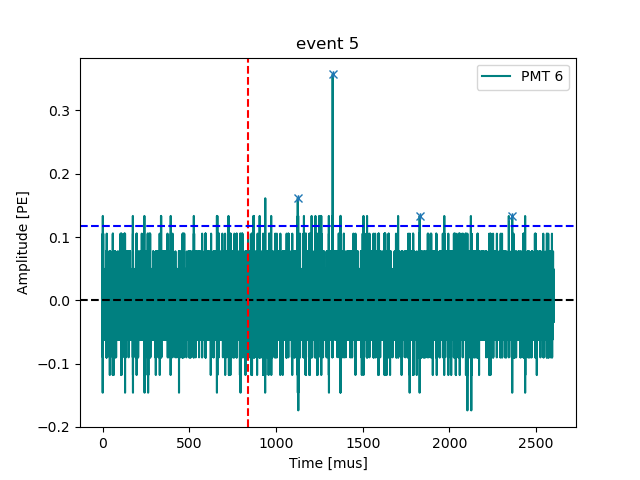

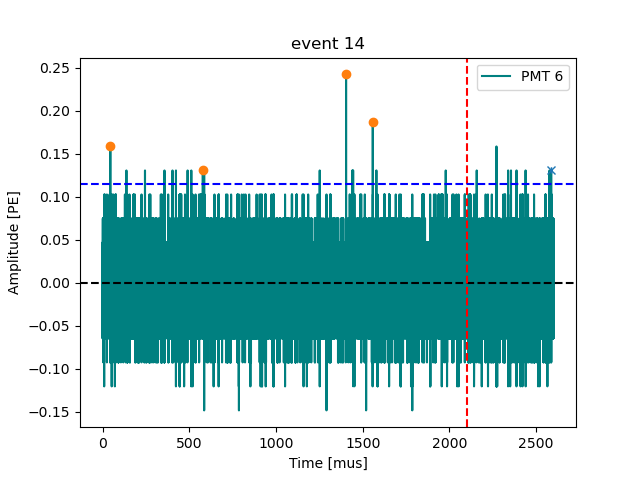

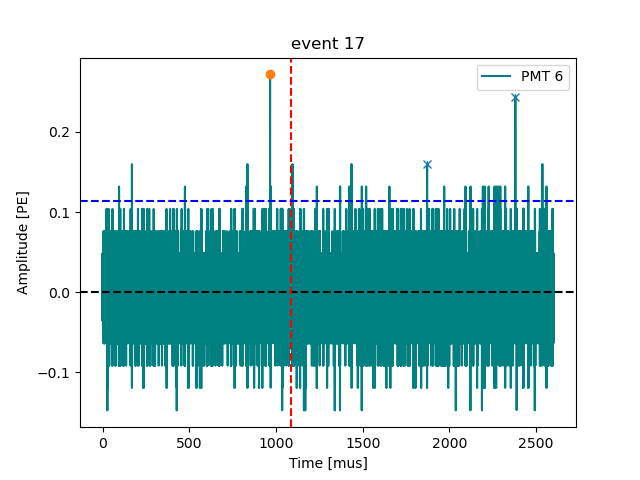

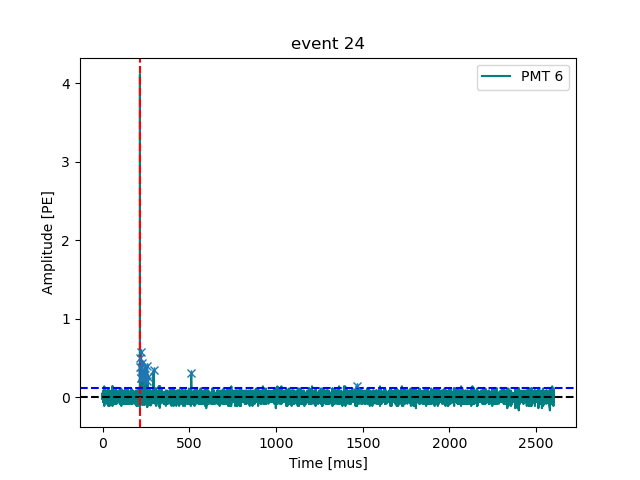

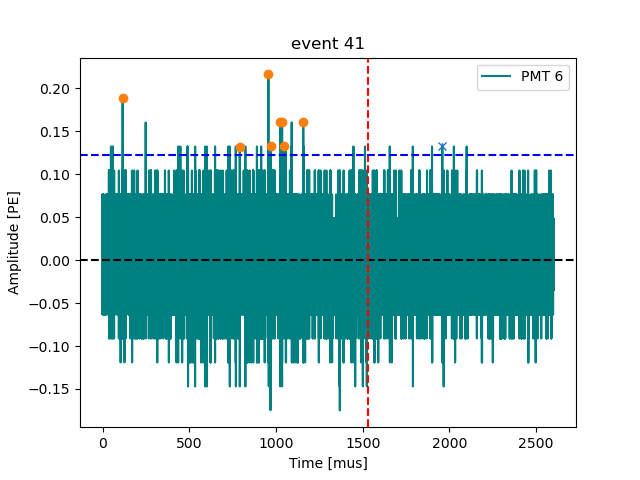

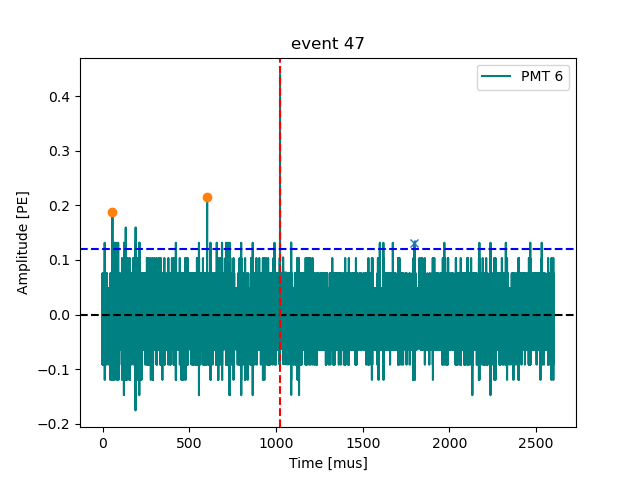

In [6]:
%matplotlib widget

event_number = 0

wf_sum_all_evts = 0

# highest = highest PMT waveform, "summed" = summed waveform across all PMT, "1-60" select PMT number for a specific pmt
# plot_mode = "highest"
# plot_mode = "summed"
plot_mode = 6

data = []

# Open the file
with tb.open_file(filename) as file:

    rwf      = file.root.RD.pmtrwf
    evt_info = file.root.Run.events
    
    # Loop over the events
    for evt_no, wfs in enumerate(rwf):

        evt_id = evt_info[evt_no][0]
        _, ts = evt_info[evt_no]
        
        # if (evt_no != event_number):
        #     continue

        print("On Event:", evt_no, "real ID:", evt_info[evt_no][0])

        wfs = deconv(wfs)

        # Convert the ADC to PE
        wfs = ADC_to_PE(wfs, datapmt)

        # Zero out the dead PMTs
        for pmt_ in dead_pmts:
            wfs[pmt_] = np.arange(wfs[pmt_] .size) * 0
        
        sp_sipm = 1     # sampling period in mus
        times   = np.arange(wfs[0] .size) * tc


        # Choose which waveform to plot
        if (plot_mode == "highest"):
            index = np.argmax(np.max(wfs, axis=1))
            wf_pmt = wfs[index]
            plot_mode = index
            wfs_sum = sum_wf(wfs)
        elif (plot_mode == "summed"):
            wf_pmt =  sum_wf(wfs)
            wfs_sum  = wf_pmt
        else:
            wf_pmt = wfs[int(plot_mode)]
            wfs_sum = sum_wf(wfs)

        S1, _ = find_peaks(wfs_sum[ int(S1_window[0]/tc):int(S1_window[1]/tc)], height=S1_height, distance=10/tc)
        print(S1*tc)


        print("S1 peaks:", len(S1))

        if (len(S1) != 1):
            print("No S1 or too many S1s!")
            continue
        else:
            print(f"event {evt_no}: S1s:", len(S1))

        if (S1[0]*tc < 100):
            print("S1 too early, dropping event")
            continue

        # Calculate the noise of the PMT 
        noise_lim[1] = S1[0]*tc - 5*tc
        noise = []
        for pmt_no, wf in enumerate(wfs):
            noise.append(noise_sigma*np.std(wf[int(noise_lim[0]/tc):int(noise_lim[1]/tc)]))

        # Search for single PEs 2 mus after the S1 peak 
        grass_lim[0] = S1[0]*tc + S1_pad

        # Search for S1 in the window of S1_pad after the S1 peak
        S1_lim = list([S1[0]*tc, S1[0]*tc + S1_pad])

        # df = get_PEs_inWindow(times, wfs, noise, thr_split, peak_minlen, peak_maxlen, half_window, grass_lim, evt_id, ts, tc)
        df       = get_charge_inWindow(times, wfs, noise, thr_split, peak_minlen, peak_maxlen, 2, grass_lim, evt_id, tc, "S1_tail")
        noise_df = get_charge_inWindow(times, wfs, noise, thr_split, peak_minlen, peak_maxlen, 2, noise_lim, evt_id, tc, "noise")
        S1_df    = get_charge_inWindow(times, wfs, noise, thr_split, peak_minlen, peak_maxlen, 2, S1_lim,    evt_id, tc, "S1")

        
        plt.figure()
        plt.plot(times, wf_pmt , label = f"PMT {plot_mode}",  color = "Teal");
        plt.ylabel("Amplitude [PE]")
        plt.xlabel("Time [mus]")
        plt.axhline(y=0, color='black', linestyle='--')
        plt.legend(loc = "upper right")
        plt.title(f"event {evt_no}")

        sel = df[df.pmt == plot_mode]
        sel_noise = noise_df[noise_df.pmt == plot_mode]
        plt.errorbar(sel.peak_time, sel.peak_height, xerr=[sel.peak_time - sel.int_start, sel.int_end - sel.peak_time], fmt='x', capsize=2, label='Peaks')
        plt.errorbar(sel_noise.peak_time, sel_noise.peak_height, xerr=[sel_noise.peak_time - sel_noise.int_start, sel_noise.int_end - sel_noise.peak_time], fmt='o', capsize=2, label='Noise Peaks')

        plt.axvline(x=S1[0] * tc, color='red', linestyle='--', label='S1 Peak')
        plt.axhline(y=noise[plot_mode], color='blue', linestyle='--', label='noise theshold')

        # Correct the peak time to be relative to the S1 peak
        df.peak_time       = df.peak_time       - grass_lim[0]
        noise_df.peak_time = noise_df.peak_time - noise_lim[0]
        S1_df.peak_time    = S1_df.peak_time    - S1_lim[0]
        data.append(df)
        data.append(noise_df)
        data.append(S1_df)


data     = pd.concat([d for d in data if len(d)], ignore_index=True)

In [7]:
display(data)
print(data.event.unique())

,event,pmt,pe_int,peak_time,peak_width,peak_height,int_start,int_end,win_start,win_end,noise_thr,label
0,36,0,0.005049,31.8375,0.050,0.130773,871.225,871.350,839.450,2600.000,0.121945,S1_tail
1,36,0,0.031066,167.2125,0.100,0.325162,1006.575,1006.750,839.450,2600.000,0.121945,S1_tail
2,36,0,0.003664,1087.4375,0.050,0.130786,1926.825,1926.950,839.450,2600.000,0.121945,S1_tail
3,36,0,0.005052,1397.6125,0.050,0.130790,2237.000,2237.125,839.450,2600.000,0.121945,S1_tail
4,36,0,0.031063,1507.9375,0.100,0.325303,2347.300,2347.475,839.450,2600.000,0.121945,S1_tail
...,...,...,...,...,...,...,...,...,...,...,...,...
3089,330,52,0.024473,0.0125,0.050,0.554779,1023.175,1023.250,1023.175,1024.175,0.116495,S1
3090,330,53,0.041452,0.7000,0.125,0.456961,1023.775,1023.975,1023.175,1024.175,0.116026,S1
3091,330,54,0.084000,0.1375,0.200,0.587538,1023.175,1023.450,1023.175,1024.175,0.130326,S1
3092,330,55,0.037215,0.0500,0.125,0.325331,1023.175,1023.325,1023.175,1024.175,0.109144,S1


[ 36  99 120 169 288 330]


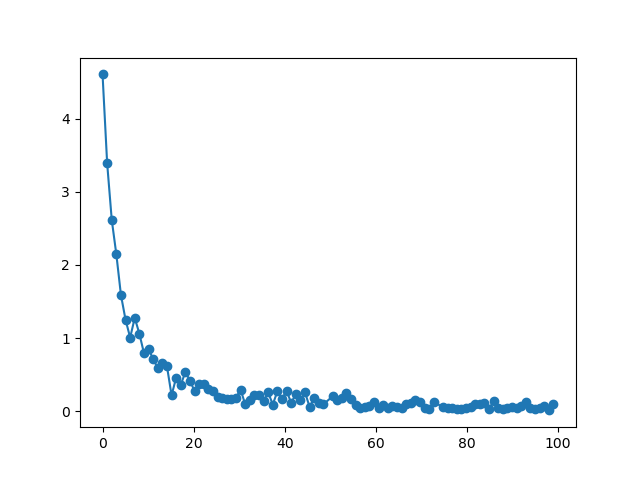

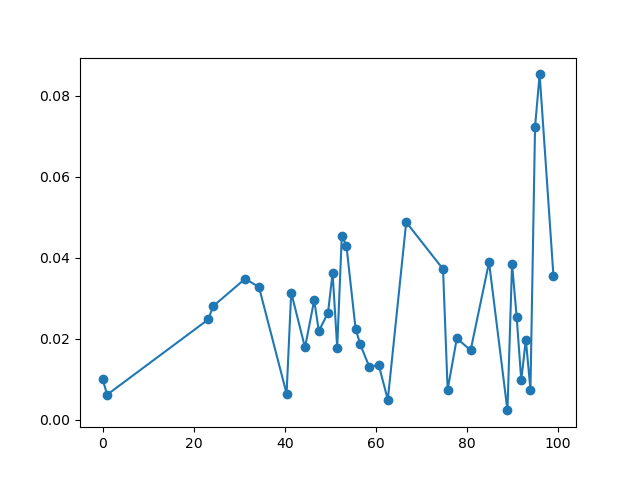

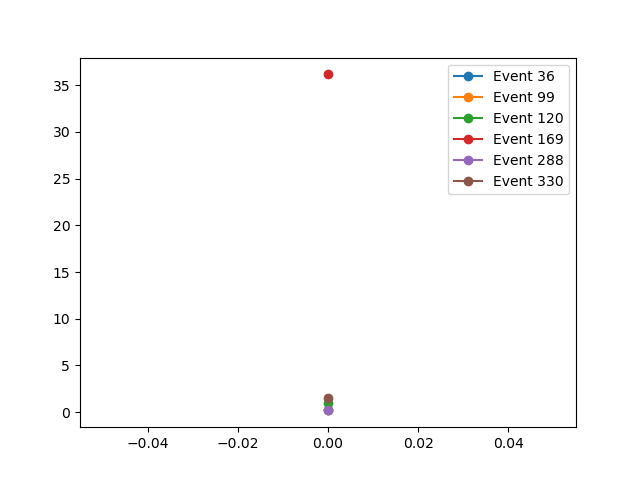

In [9]:
bins = np.linspace(0, 100, 100) 

data['peak_time_bin'] = pd.cut(data['peak_time'], bins, include_lowest=True, labels=bins[:-1])

tail_data = data[data.label == "S1_tail"]
noise_data = data[data.label == "noise"]
S1_data = data[data.label == "S1"]


grouped = tail_data.groupby(['peak_time_bin'])['pe_int'].sum().reset_index()

plt.figure()
plt.plot(grouped['peak_time_bin'], grouped['pe_int'], marker='o', linestyle='-')

grouped_noise = noise_data.groupby(['peak_time_bin'])['pe_int'].sum().reset_index()

plt.figure()
plt.plot(grouped_noise['peak_time_bin'], grouped_noise['pe_int'], marker='o', linestyle='-')

grouped_S1 = S1_data.groupby(['event', 'peak_time_bin'])['pe_int'].sum().reset_index()
plt.figure()
for event in grouped_S1['event'].unique():
    event_data = grouped_S1[grouped_S1['event'] == event]
    plt.plot(event_data['peak_time_bin'], event_data['pe_int'], marker='o', linestyle='-', label=f'Event {event}')
plt.legend()
